# Experiment 02: Text Preprocessing Techniques
**NLP Lab (COMP-441L)** · PAF-IAST

Name: __Najam_Iqbal__   Roll No: _B23F0001CS058_

**Objectives:** lowercasing, cleaning, tokenization (NLTK, Stanza), stopwords, stemming, lemmatization, POS tagging, chunking, emojis, minimum edit distance, and simple charts.

**How to work:** run each code cell (Shift+Enter), compare with what you expect, then do the **Your turn** steps. Total: 100 marks.

*Version with sample outputs saved, so you can see what each cell should show.*

## Setup
Run the install cell once, then the download cell.

In [1]:
!pip install -q nltk stanza emoji pandas matplotlib seaborn


[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import nltk
for pkg in ["punkt_tab", "stopwords", "wordnet", "omw-1.4", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg)

[nltk_data] Error loading punkt_tab: <urlopen error pathsec.urlopen:
[nltk_data]     no validated address for host
[nltk_data]     'raw.githubusercontent.com'; refusing to connect by
[nltk_data]     unvalidated hostname>
[nltk_data] Error loading stopwords: <urlopen error pathsec.urlopen:
[nltk_data]     no validated address for host
[nltk_data]     'raw.githubusercontent.com'; refusing to connect by
[nltk_data]     unvalidated hostname>
[nltk_data] Error loading wordnet: <urlopen error pathsec.urlopen: no
[nltk_data]     validated address for host
[nltk_data]     'raw.githubusercontent.com'; refusing to connect by
[nltk_data]     unvalidated hostname>
[nltk_data] Error loading omw-1.4: <urlopen error pathsec.urlopen: no
[nltk_data]     validated address for host
[nltk_data]     'raw.githubusercontent.com'; refusing to connect by
[nltk_data]     unvalidated hostname>
[nltk_data] Error loading averaged_perceptron_tagger_eng: <urlopen
[nltk_data]     error pathsec.urlopen: no validated a

## Task 1: Charts with Matplotlib and seaborn (10 marks)
**Step A:** create the student table.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({
    "Name":     ["Ali","Sara","Hamza","Ayesha","Bilal","Fatima","Usman","Zainab","Omar","Hira",
                 "Saad","Mariam","Talha","Noor","Daniyal","Imran","Haris","Maham","Shahid","Rehan"],
    "Gender":   ["M","F","M","F","M","F","M","F","M","F","M","F","M","F","M","M","M","F","M","M"],
    "Age":      [19,20,21,19,22,20,21,23,19,20,22,21,20,19,21,22,20,23,21,19],
    "Domicile": ["Punjab","KPK","KPK","Punjab","Sindh","Punjab","KPK","Islamabad","Punjab","KPK",
                 "Sindh","Punjab","KPK","Islamabad","Punjab","KPK","Sindh","Punjab","KPK","Punjab"],
})
print(df.head())

     Name Gender  Age Domicile
0     Ali      M   19   Punjab
1    Sara      F   20      KPK
2   Hamza      M   21      KPK
3  Ayesha      F   19   Punjab
4   Bilal      M   22    Sindh


**Step B:** pie chart for Gender.

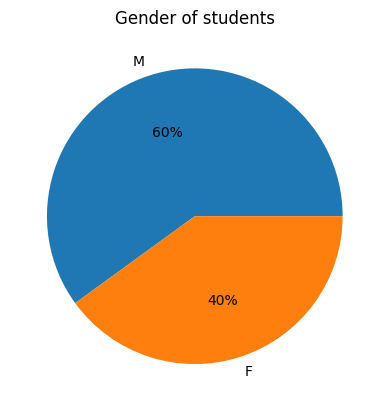

In [3]:
# Pie chart for Gender
gender_counts = df["Gender"].value_counts()
plt.pie(gender_counts, labels=gender_counts.index, autopct="%1.0f%%")
plt.title("Gender of students")
plt.show()

**Step C:** bar chart for Age.

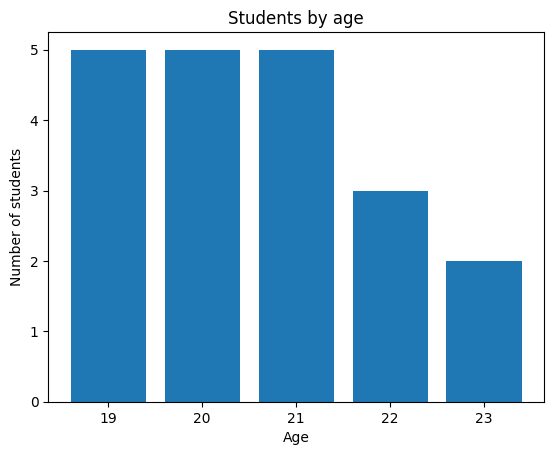

In [4]:
# Bar chart for Age
age_counts = df["Age"].value_counts().sort_index()
plt.bar(age_counts.index.astype(str), age_counts.values)
plt.xlabel("Age")
plt.ylabel("Number of students")
plt.title("Students by age")
plt.show()

**Step D:** bar chart for Domicile using seaborn.

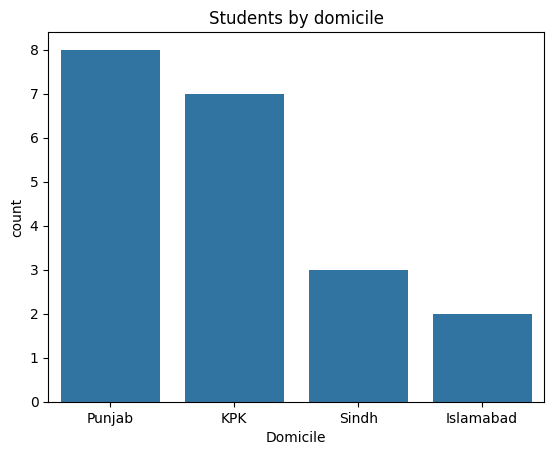

In [5]:
# Bar chart for Domicile (using seaborn)
sns.countplot(data=df, x="Domicile")
plt.title("Students by domicile")
plt.show()

`value_counts()` counts how many times each value appears. `plt.pie` draws the pie; `autopct` prints percentages. `plt.bar` draws a bar chart. `sns.countplot` counts and draws in one line.

**Your turn:**

1. Which gender has more students and what percentage is it? (one sentence)
2. Which age(s) have the most students?
3. Which domicile has the most students and which has the least?
4. Change the pie chart title to your own name and run it again.

*Write your answers here (double-click to edit).*

## Task 2: Lowercasing (5 marks)
`.lower()` makes every letter small so `Language` and `language` become the same word.

In [2]:
text = "Natural Language Processing is FUN! NLP helps Computers understand Human Language."
print("Original :", text)
print("Lowercase:", text.lower())

Original : Natural Language Processing is FUN! NLP helps Computers understand Human Language.
Lowercase: natural language processing is fun! nlp helps computers understand human language.


**Your turn:**

1. Write a sentence of your own with at least 3 capital letters and lowercase it.
2. Try `.upper()` and `.title()` on your sentence. What do they do?
3. Why do we lowercase text before analysing it? (one sentence)

ANSWER: We do lowercase text before analysing to bring all the text to same scale as text in lowercase has same meaning as in Capital i.e. "the" is same as "THE" and "The". So it is useful to keep all the text in same lower case to avoid inconvinience as Model can provide different meanings to same word due to its different in casing.

In [3]:
# your code here
text="We are in NLP Lab. We are doing NLP lab#2"
print("Lower case: ", text.lower())
print("Title: ", text.title())
print("Upper case: ", text.upper())

Lower case:  we are in nlp lab. we are doing nlp lab#2
Title:  We Are In Nlp Lab. We Are Doing Nlp Lab#2
Upper case:  WE ARE IN NLP LAB. WE ARE DOING NLP LAB#2


## Task 3: Text cleaning (10 marks)
`clean_text` is a small reusable function. The five lines inside are the five cleaning steps. `re.sub(pattern, replacement, text)` replaces everything that matches the pattern.

Side effect: `Khan's` becomes `khan s` because the apostrophe is removed.

In [4]:
import re

def clean_text(text):
    text = text.lower()                                     # 1. make everything lowercase
    text = re.sub(r"<.*?>", " ", text)                      # 2. remove HTML tags like <p>
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)      # 3. remove web links
    text = re.sub(r"[^a-z0-9\s]", " ", text)                   # 4. remove digits, punctuation, emojis
    text = re.sub(r"\s+", " ", text).strip()                # 5. remove extra spaces
    return text

corpus = [
    "<p>I LOVED this phone!!! Battery lasts 2 days :) Visit https://example.com for more.</p>",
    "The camera is not good, and the screen cracked after 3 weeks...",
    "Dr. Khan's students are running experiments on NLP models.",
]

for sentence in corpus:
    print(clean_text(sentence))

i loved this phone battery lasts 2 days visit for more
the camera is not good and the screen cracked after 3 weeks
dr khan s students are running experiments on nlp models


**Your turn:**

1. Add one sentence of your own to `corpus` with a web link, a number and a smiley `:)`. Run again.
2. Write down which parts were removed from your sentence.
3. In step 4 change `[^a-z\s]` to `[^a-z0-9\s]`. What changes in the output?

ANSWER:

1. Changes are made in successive cell.
2. Link was removed, special characters : ) were removed and numerical values were also removed from new sentence.

3. After changing [^a-z\s] to [^a-z0-9\s], we got numerical values in output as well. Earlier we were elimintig numerical values by expression from Regular Expression [^a-z\s].

In [5]:
corpus=corpus = [
    "<p>I LOVED this phone!!! Battery lasts 2 days :) Visit https://example.com for more.</p>",
    "The camera is not good, and the screen cracked after 3 weeks...",
    "Dr. Khan's students are running experiments on NLP models.",
    "You can buy COMPUTER components from: https://www.bing.com/alink/link?url=https%3A%2F%2Fwww.booking.com%2. there is offer for 25 days :)"
]

for sentence in corpus:
    print(clean_text(sentence))



i loved this phone battery lasts 2 days visit for more
the camera is not good and the screen cracked after 3 weeks
dr khan s students are running experiments on nlp models
you can buy computer components from there is offer for 25 days


## Task 4: Tokenization with NLTK and Stanza (12 marks)
**Part A: NLTK.** `sent_tokenize` splits into sentences; `word_tokenize` splits into words (punctuation and emojis become tokens too).

Notice that NLTK keeps `Dr.` and `a.m.` together, and splits `isn't` into `is` + `n't` and `He'll` into `He` + `'ll`.

In [6]:
from nltk.tokenize import sent_tokenize, word_tokenize

text = "Dr. Smith isn't available today. He'll arrive tomorrow at 10 a.m. 😊. You are free to leave Today."

print("Sentences:", sent_tokenize(text))
print("Words    :", word_tokenize(text))

Sentences: ["Dr. Smith isn't available today.", "He'll arrive tomorrow at 10 a.m. 😊.", 'You are free to leave Today.']
Words    : ['Dr.', 'Smith', 'is', "n't", 'available', 'today', '.', 'He', "'ll", 'arrive', 'tomorrow', 'at', '10', 'a.m.', '😊', '.', 'You', 'are', 'free', 'to', 'leave', 'Today', '.']


**Part B: Stanza.** The first run downloads a model, so it takes a while and needs internet. Its output may differ a little from NLTK's: the aim is to compare them.

In [11]:
import stanza
stanza.download("en")                                  # needed only the first time
nlp = stanza.Pipeline("en", processors="tokenize")

doc = nlp(text)
for sentence in doc.sentences:
    print("Sentence:", sentence.text)
    print("Words   :", [token.text for token in sentence.tokens])

2026-10-11 18:11:38 INFO: Downloaded file to C:\Users\najam\AppData\Local\StanfordNLP\stanza\Cache\1.15.0\resources\resources.json
2026-10-11 18:11:38 INFO: Downloading default packages for language: en (English) ...
2026-10-11 18:11:41 INFO: File exists: C:\Users\najam\AppData\Local\StanfordNLP\stanza\Cache\1.15.0\resources\en\default.zip
2026-10-11 18:11:46 INFO: Finished downloading models and saved to C:\Users\najam\AppData\Local\StanfordNLP\stanza\Cache\1.15.0\resources
2026-10-11 18:11:46 INFO: Checking for updates to resources.json in case models have been updated.  Note: this behavior can be turned off with download_method=None or download_method=DownloadMethod.REUSE_RESOURCES
2026-10-11 18:11:53 INFO: Downloaded file to C:\Users\najam\AppData\Local\StanfordNLP\stanza\Cache\1.15.0\resources\resources.json
2026-10-11 18:11:53 WARNING: Language en package default expects mwt, which has been added
2026-10-11 18:11:53 INFO: Loading these models for language: en (English):
| Process

Sentence: Dr. Smith isn't available today.
Words   : ['Dr.', 'Smith', "isn't", 'available', 'today', '.']
Sentence: He'll arrive tomorrow at 10 a.m. 😊.
Words   : ["He'll", 'arrive', 'tomorrow', 'at', '10', 'a.m.', '😊.']
Sentence: You are free to leave Today.
Words   : ['You', 'are', 'free', 'to', 'leave', 'Today', '.']


**Your turn:**

1. Run `print(text.split("."))`. Write what goes wrong with `Dr.` and `a.m.`.
2. Fill the table below for NLTK and Stanza.
3. Which tool do you prefer for this text, and why? (one sentence)

ANSWER:
1. We got Dr and am while using print(text.split(".")). This output is wrong as correct words are Dr. and a.m. are correct.
2. Table filled.
3. I prefer Stanza over NLTK as it generates more accurate and natural as it uses DeepLearning for ensuring that token generated is meannigful.

| Item | NLTK | Stanza |
|---|---|---|
| `Dr.` | Dr. | Dr. |
| `isn't` | "is" & "n't" | isn't |
| `He'll` | 'He' & "'ll" | He'll |
| `a.m.` | a.m. | a.m. |
| the emoji 😊 | 😊 | 😊 |

In [12]:
print(text.split("."))

['Dr', " Smith isn't available today", " He'll arrive tomorrow at 10 a", 'm', ' 😊', ' You are free to leave Today', '']


## Task 5: Stopword removal (8 marks)
`stopwords.words("english")` is a ready-made list of common words. `[w for w in words if w not in stop_words]` keeps a word only if it is **not** a stopword.

In [13]:
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

stop_words = set(stopwords.words("english"))

sentence = "this is a simple example to show how stopwords are removed from a sentence as We are learning how to remove stopwords."
words = word_tokenize(sentence)
filtered = [w for w in words if w not in stop_words]

print("Before :", words)
print("After  :", filtered)
print("Removed:", len(words) - len(filtered), "words")

Before : ['this', 'is', 'a', 'simple', 'example', 'to', 'show', 'how', 'stopwords', 'are', 'removed', 'from', 'a', 'sentence', 'as', 'We', 'are', 'learning', 'how', 'to', 'remove', 'stopwords', '.']
After  : ['simple', 'example', 'show', 'stopwords', 'removed', 'sentence', 'We', 'learning', 'remove', 'stopwords', '.']
Removed: 12 words


**Your turn:**

1. Change `sentence` to your own lowercase sentence. How many words were removed?
2. Now use `sentence = "the movie was not good"`. What words are left?
3. Did the meaning change? Why can this be a problem?

ANSWERS
1. Seven words were removed
2. Only "movie" and "good"
3. Yes, meaning changed completely: Original sentence was saying movie was not good but after removing stopwords, this sentence is conveying that movie was good.

In [ ]:
# your code here
sentence = "We are doing this learning activity as this is assigned to us"
words = word_tokenize(sentence)
filtered = [w for w in words if w not in stop_words]

print("1-")
print("Before :", words)
print("After  :", filtered)
print("Removed:", len(words) - len(filtered), "words")

print("\n\n2-")
sentence = "the movie was not good"
words = word_tokenize(sentence)
filtered = [w for w in words if w not in stop_words]
print("Before :", words)
print("After  :", filtered)
print("Removed:", len(words) - len(filtered), "words")

1-
Before : ['We', 'are', 'doing', 'this', 'learning', 'activity', 'as', 'this', 'is', 'assigned', 'to', 'us']
After  : ['We', 'learning', 'activity', 'assigned', 'us']
Removed: 7 words


2-
Before : ['the', 'movie', 'was', 'not', 'good']
After  : ['movie', 'good']
Removed: 3 words


## Task 6: Stemming (8 marks)
A **stemmer** chops word endings using simple rules, so the result is not always a real word (`easili`, `studi`). `PorterStemmer` is gentle; `LancasterStemmer` is more aggressive.

In [16]:
from nltk.stem import PorterStemmer, LancasterStemmer

porter = PorterStemmer()
lancaster = LancasterStemmer()

words = ["running", "runs", "easily", "studies", "connected", "connection", "happiness", "better", "ease"]

print(f"{'word':12s} {'Porter':10s} {'Lancaster':10s}")
for w in words:
    print(f"{w:12s} {porter.stem(w):10s} {lancaster.stem(w):10s}")

word         Porter     Lancaster 
running      run        run       
runs         run        run       
easily       easili     easy      
studies      studi      study     
connected    connect    connect   
connection   connect    connect   
happiness    happi      happy     
better       better     bet       
ease         eas        eas       


**Your turn:**

1. Write down 3 stems that are **not** real words.
2. Add 4 words of your own to `words` and run again.
3. Which stemmer cut more letters overall, Porter or Lancaster?

ANSWERS:
1. I added "wondr", "dfsdfs" and "qwert" which are meannigless.
2. I added 4 meaningful words "avoid", "happiness", "quickest" and "similarly".
3. Lancaster is cutting more letters. It has more iterations at backend so it is overcutting.

In [20]:
porter = PorterStemmer()
lancaster = LancasterStemmer()

words = ["wondr", "dfsdfs", "qwert", "avoid", "happiness", "quickest", "similarly"]

print(f"{'word':12s} {'Porter':10s} {'Lancaster':10s}")
for w in words:
    print(f"{w:12s} {porter.stem(w):10s} {lancaster.stem(w):10s}")

word         Porter     Lancaster 
wondr        wondr      wondr     
dfsdfs       dfsdf      dfsdfs    
qwert        qwert      qwert     
avoid        avoid      avoid     
happiness    happi      happy     
quickest     quickest   quickest  
similarly    similarli  simil     


## Task 7: Part-of-speech (POS) tagging (10 marks)
`word_tokenize` splits the sentence and `pos_tag` gives each word a tag.

| Tag | Meaning | Example | Tag | Meaning | Example |
|---|---|---|---|---|---|
| NN | noun (one) | dog | VB | verb (base) | run |
| NNS | nouns (many) | dogs | VBD | verb (past) | ran |
| NNP | name | Ali | VBZ | verb (he/she/it) | runs |
| JJ | adjective | lazy | VBG | verb (-ing) | running |
| DT | the / a | the | RB | adverb | quickly |
| IN | preposition | over | PRP | pronoun | she |

In [14]:
from nltk import pos_tag
from nltk.tokenize import word_tokenize

sentence = "The quick brown fox jumps over the lazy dog"
tokens = word_tokenize(sentence)
tagged = pos_tag(tokens)

for word, tag in tagged:
    print(f"{word:8s} {tag}")

The      DT
quick    JJ
brown    NN
fox      NN
jumps    VBZ
over     IN
the      DT
lazy     JJ
dog      NN


**Your turn:**

1. Use the table to write the meaning of the tags for `The`, `quick`, `fox`, `jumps` and `over`.
2. Change `sentence` to your own sentence (at least 8 words) and run it.
3. Pick one word from your result and say whether its tag is correct.

ANSWERS:
1. The:DT quick:JJ fox:NN jumps:VBZ over:IN
2. I added sentence: "Pakistan's economy is facing severe challenges due to poor governance".
3. In output, "severe" is tagged JJ (adjective), which is correct because it modifies the noun "challenges".

In [24]:
from nltk import pos_tag
from nltk.tokenize import word_tokenize

sentence = "Pakistan's economy is facing severe challenges due to poor governance"
tokens = word_tokenize(sentence)
tagged = pos_tag(tokens)

for word, tag in tagged:
    print(f"{word:8s} {tag}")

Pakistan NNP
's       POS
economy  NN
is       VBZ
facing   VBG
severe   JJ
challenges NNS
due      JJ
to       TO
poor     JJ
governance NN


## Task 8: Lemmatization (10 marks)
A **lemmatizer** looks the word up in a dictionary (WordNet) and gives the real base word (the **lemma**). Tell it the part of speech: `n` = noun, `v` = verb, `a` = adjective. Without it, every word is treated as a noun.

In [26]:
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

# by default every word is treated as a noun
print(lemmatizer.lemmatize("running"))
print(lemmatizer.lemmatize("running", pos="v"))     # now we say it is a verb

# n = noun, v = verb, a = adjective
examples = [("cars", "n"), ("studies", "n"), ("studies", "v"), ("was", "v"), ("better", "a"), ("walking", "v"),("stripes", "v")]
for word, pos in examples:
    print(f"{word:8s} ({pos}) -> {lemmatizer.lemmatize(word, pos=pos)}")

running
run
cars     (n) -> car
studies  (n) -> study
studies  (v) -> study
was      (v) -> be
better   (a) -> good
walking  (v) -> walk
stripes  (v) -> strip


**Your turn:**

1. Try 4 words of your own (for example `children`, `went`, `happier`, `eating`) with the right `pos`.
2. Compare with Task 6: what did the stemmer give for `studies` and what does the lemmatizer give?
3. What is the difference between stemming and lemmatization? (one sentence)

ANSWERS:
1. I tried ("birds", "n"), ("forgotten", "v"), ("quickest", "a"), ("playing", "v") below and got:

    birds    (n) -> bird

    forgotten (v) -> forget

    quickest (a) -> quick

    playing  (v) -> play

2. For studies  (v), i got "study" for both stemming and lemmatization.
3. Stemming is rule based striping and may not give meaningful always while Lemmatization is Dictionary lookup based stripping and it always give meaningful word.

In [33]:
# n = noun, v = verb, a = adjective
examples = [("birds", "n"), ("forgotten", "v"), ("quickest", "a"), ("playing", "v"), ("studies", "v")]
for word, pos in examples:
    print(f"{word:8s} ({pos}) -> {lemmatizer.lemmatize(word, pos=pos)}")

birds    (n) -> bird
forgotten (v) -> forget
quickest (a) -> quick
playing  (v) -> play
studies  (v) -> study


## Task 9: Chunking (10 marks)
**Tokenization** cuts text into words or sentences. **Chunking** groups those words into meaningful units (noun and verb phrases).

The grammar `NP: {<DT>?<JJ>*<NN.*>+}` means: an optional determiner, any number of adjectives, then one or more nouns. If `tree.draw()` does not open a window, use `pretty_print()` as below.

In [36]:
import nltk
from nltk import pos_tag
from nltk.tokenize import word_tokenize

sentence = "The old teacher reads a long book"
tagged = pos_tag(word_tokenize(sentence))

# NP = optional determiner (DT), any adjectives (JJ), then one or more nouns (NN...)
grammar = "NP: {<DT>?<JJ>*<NN.*>+}"
parser = nltk.RegexpParser(grammar)
tree = parser.parse(tagged)

tree.pretty_print()

for subtree in tree.subtrees():
    if subtree.label() == "NP":
        print("Noun phrase:", " ".join(word for word, tag in subtree.leaves()))

                            S                          
     _______________________|______________             
    |              NP                      NP          
    |        ______|________         ______|_______     
reads/VBZ The/DT old/JJ teacher/NN a/DT long/JJ book/NN

Noun phrase: The old teacher
Noun phrase: a long book


**Your turn:**

1. Change `sentence` to "The old teacher reads a long book". List the noun phrases found.
2. Replace the grammar by the two-line version in the next cell to also find verb phrases. What new chunk appears?
3. What is the difference between tokenization and chunking? (one sentence)

ANSWERS:
1. I got follwing:

    Noun phrase: The old teacher

    Noun phrase: a long book

2. Following new chunk appeared:

    Verb phrase: reads

3. Tokenization breaks raw text into pieces while chunking inputs those pieces+tags to generate meaningful phrases.

In [37]:
sentence = "The old teacher reads a long book"
tagged = pos_tag(word_tokenize(sentence))

# NP = optional determiner (DT), any adjectives (JJ), then one or more nouns (NN...)
grammar = """
NP: {<DT>?<JJ>*<NN.*>+}
VP: {<VB.*>+}
"""

parser = nltk.RegexpParser(grammar)
tree = parser.parse(tagged)

tree.pretty_print()

for subtree in tree.subtrees():
    if subtree.label() == "NP":
        print("Noun phrase:", " ".join(word for word, tag in subtree.leaves()))
    elif subtree.label() == "VP":
        print("Verb phrase:", " ".join(word for word, tag in subtree.leaves()))

                             S                         
          ___________________|_____________             
         NP                  VP            NP          
   ______|________           |       ______|_______     
The/DT old/JJ teacher/NN reads/VBZ a/DT long/JJ book/NN

Noun phrase: The old teacher
Verb phrase: reads
Noun phrase: a long book


In [ ]:
grammar = """
NP: {<DT>?<JJ>*<NN.*>+}
VP: {<VB.*>+}
"""

## Task 10: Replacing emojis with text (7 marks)
`emoji.demojize` replaces each emoji with its name between colons; `emoji.emoji_count` counts them. Our function `emoji_to_text` turns the names into plain words.

In [39]:
import emoji

text = "Great job 😊👍😃 I love it 👍👌✌️ "

print(emoji.demojize(text))            # emoji become :names:
print("Number of emojis:", emoji.emoji_count(text))

# nicer version: remove the colons and underscores
def emoji_to_text(text):
    result = emoji.demojize(text, delimiters=(" ", " "))
    return " ".join(result.replace("_", " ").split())

print(emoji_to_text(text))

Great job :smiling_face_with_smiling_eyes::thumbs_up::grinning_face_with_big_eyes: I love it :thumbs_up::OK_hand::victory_hand: 
Number of emojis: 6
Great job smiling face with smiling eyes thumbs up grinning face with big eyes I love it thumbs up OK hand victory hand


**Your turn:**

1. Change `text` to a sentence with 3 different emojis and run the cell.
2. How many emojis were counted?
3. Why can turning emojis into words help when we analyse comments? (one sentence)

ANSWERS:
1. I changed sentence to: "Excellent 👌  I appreciate your efforts 👍 May you succeed ✌️".
2. Number of emojis: 3.
3. Generally Emojis are discarded by text-based models. So, we must have to turn emojis into respective text description help text-based models to analize emojis.

In [40]:

text = "Excellent 👌  I appreciate your efforts 👍 May you succeed ✌️"

print(emoji.demojize(text))            # emoji become :names:
print("Number of emojis:", emoji.emoji_count(text))

# nicer version: remove the colons and underscores
def emoji_to_text(text):
    result = emoji.demojize(text, delimiters=(" ", " "))
    return " ".join(result.replace("_", " ").split())

print(emoji_to_text(text))

Excellent :OK_hand:  I appreciate your efforts :thumbs_up: May you succeed :victory_hand:
Number of emojis: 3
Excellent OK hand I appreciate your efforts thumbs up May you succeed victory hand


## Task 11: Minimum edit distance (10 marks)
Three changes, each costing 1: **insert**, **delete**, **substitute**. `cat` to `cut` needs 1 change. `kitten` to `sitting` needs 3 (k to s, e to i, insert g).

`table[i][j]` stores the distance between the first `i` letters of word 1 and the first `j` letters of word 2. The three numbers inside `min(...)` are delete, insert and substitute; the cheapest is taken.

In [42]:
def min_edit_distance(a, b):
    n, m = len(a), len(b)
    # table[i][j] = distance between the first i letters of a and the first j letters of b
    table = [[0] * (m + 1) for _ in range(n + 1)]
    for i in range(n + 1):
        table[i][0] = i                      # i deletions
    for j in range(m + 1):
        table[0][j] = j                      # j insertions
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            if a[i - 1] == b[j - 1]:
                cost = 0                     # same letter, nothing to change
            else:
                cost = 1                     # different letter, substitute
            table[i][j] = min(table[i - 1][j] + 1,          # delete
                              table[i][j - 1] + 1,          # insert
                              table[i - 1][j - 1] + cost)   # substitute (or keep)
    return table[n][m]

pairs = [("cat", "cat"), ("cat", "cut"), ("book", "back"), ("kitten", "sitting"), ("sunday", "saturday")]
for a, b in pairs:
    print(f"{a:8s} -> {b:9s} distance = {min_edit_distance(a, b)}")

cat      -> cat       distance = 0
cat      -> cut       distance = 1
book     -> back      distance = 2
kitten   -> sitting   distance = 3
sunday   -> saturday  distance = 3


**Your turn:**

1. **Guess first** the distance for `dog` to `dig` and `sit` to `sat`, then add them to `pairs` and check.
2. Add 3 more pairs of your own and run the cell.
3. Fill a table: word 1, word 2, your guess, the program's answer.
4. Which change (insert, delete or substitute) turns `book` into `back`, and how many changes are needed?

ANSWERS:
1.   dog ---> dig,   Guessed disctance= 1

     sit ---> sat,   Guessed disctance= 1

2. Added 3 more pairs:

    ("sad", "bat")

    ("witness", "weakness")

    ("bold", "cold")

3.   dog ---> dig,   Guessed disctance= 1,   program's answer= 1

     sit ---> sat,   Guessed disctance= 1,   program's answer= 1

4. We can convert "book" into "back". They have distance of 2. We have to use 2 Substitutions i.e. 2nd letter: o ---> a and third letter: o ---> c to change book into back.

In [45]:
pairs = [("dog","dig"), ("sit","sat"),("sad", "bat"),("witness", "weakness"),("bold", "cold")]
for a, b in pairs:
    print(f"{a:8s} -> {b:9s} distance = {min_edit_distance(a, b)}")

dog      -> dig       distance = 1
sit      -> sat       distance = 1
sad      -> bat       distance = 2
witness  -> weakness  distance = 3
bold     -> cold      distance = 1


## Common problems
- `LookupError`: run the NLTK download cell.
- No chart appears: end the cell with `plt.show()`.
- Lemmatizer does nothing: pass `pos="v"`.
- `tree.draw()` fails: use `tree.pretty_print()`.

**Marks:** T1 10 · T2 5 · T3 10 · T4 12 · T5 8 · T6 8 · T7 10 · T8 10 · T9 10 · T10 7 · T11 10 = 100

Github Link:
